In [1]:
# Implement and compare the performance of a neural network using different activation
# functions (Sigmoid, ReLU, Tanh) on the MNIST dataset. Analyze how each activation
# function affects the training process and classification accuracy.
# Tasks:
# ● Load and preprocess the MNIST dataset.
# ● Implement neural networks using Sigmoid, ReLU, and Tanh activation functions.
# ● Train and evaluate each network.
# ● Compare training times, convergence, and classification accuracy.

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [3]:
data = fetch_openml('mnist_784',version = 1,as_frame = False)
x = data.data
y = data.target.astype(int)
x,y = x[:10000],y[:10000]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

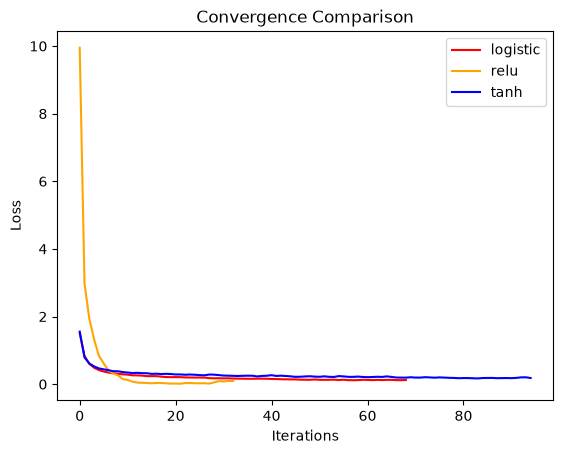

In [8]:
functions = ['logistic','relu','tanh']
colors = ['red','orange','blue']
results = []
for function,color in zip(functions,colors):
    model = MLPClassifier(hidden_layer_sizes = (100,),activation = function,max_iter = 1000,random_state = 42)
    start = time.time()
    model.fit(x_train,y_train)
    end = time.time()
    pred = model.predict(x_test)
    results.append([function,end - start,accuracy_score(y_test,pred)])
    plt.plot(model.loss_curve_,color = color,label = function)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Convergence Comparison")
plt.legend()

plt.show()

In [9]:
comparison = pd.DataFrame(results,columns = ['Function','Training time','Accuracy'])
comparison

,Function,Training time,Accuracy
0,logistic,20.675038,0.9410
1,relu,8.533086,0.9210
2,tanh,30.294656,0.9315
